# 04 — Truth probe: is there a real `is_true` feature, once the SP shortcut is gone?

Exp 1–3 verdict: the instructed-pairs probe reads "deception-relatedness of the
context" (SP token + topical content), never *actual* truth/deception of the
assertion. This experiment asks the constructive question (M&T paradigm):

> Does Qwen3-4B linearly encode whether a statement **matches its own internal
> knowledge** — a true-vs-false feature — at L20?

**Design (4a): hold the SP constant, label by `is_true`.** The mirror image of
Exp 1. There, label = persona, statement held constant → probe could only read
the SP. Here persona is held constant (honest) and label = the statement's truth
value, so the SP carries **zero** label information. (`lib.build_truth_dataset`.)

**We TRAIN A FRESH probe here** — a new LR + MM fit on `is_true`. We do **not**
reuse the Exp 1 SP-probe: pointing that at this data would give ≈0.5 by
construction (constant SP → constant score). The question is whether a truth
feature is *linearly decodable from scratch*.

**Key insight (the gear).** The RepE facts are well-known ("The largest flower is
the daisy" — false). The model *knows* the truth, so a false statement creates a
**knowledge-vs-assertion mismatch** in the residual stream. That mismatch is the
deception-relevant feature Apollo could not get from instructed-pairs alone. We
extract at the **end of the statement** (M&T §3 summarization position), and also
mean-pool to test the Exp 3 aggregation rule.

**The number that matters.** Exp 1 got 0.998 AUROC by reading the SP shortcut.
Here the shortcut is gone, so this AUROC *is* the truth-feature signal:
- **> ~0.85** → a real linear truth feature exists at L20.
- **~0.5** → no linear truth feature at this site — check a layer sweep before
  concluding it's absent (L20 is the *SP-probe* peak, not necessarily the truth one).

**No new code-gear** — reuses `fit_lr_probe` + `mm_direction`. The substance is the
*design* (above) and the *interpretation* (below) — those are yours.

**One confound to keep in mind:** presenting a false statement under "pretend
you're an honest person" is itself slightly incoherent (an honest persona stating
a falsehood). That may *sharpen* the mismatch — or the probe may read
"consistent-with-honest-persona" rather than pure truth. 4d (raw-text, no persona)
is the M&T-faithful control if this matters; note it, don't fix it yet.

## Predictions — written before running

**Setup:** TRAIN A NEW probe on the full facts corpus, all under a fixed honest SP,
labels = ground-truth `is_true`. The question is whether truth is *linearly
decodable from scratch* at L20 — not whether the Exp 1 probe transfers (it wouldn't:
constant SP → ≈0.5).

**Peter's prediction (revised for the fresh-probe setup).**
- **Test AUROC ~0.65–0.85** (LR and MM) — a real but imperfect truth feature.
- **MM ≈ LR**, MM maybe slightly better.
- **Aggregation: last-token ≥ mean.** The statement sits at the end of the input;
  the answer-bearing content is there, and averaging dilutes it.
- **Layer:** (sweep below) — peak not necessarily at L20.

**Aggregation mechanism — corrected.** mean-pool here is over the **statement tokens
only** (trailing `n_resp`), *not* the whole prompt — so there's no SP dilution. The
real reason last ≥ mean is **causal masking**: early statement tokens haven't
attended to the rest of the statement yet, so they hold partial truth-evaluations;
the final token is the one that has seen the whole thing (M&T: truth summarizes onto
the end). Averaging in the partial positions is what dilutes.

**Claude's prior:** truth feature probably present but below Exp 1's 0.998 — guess
0.80–0.92 last-token; MM ≈ LR; last ≥ mean; layer peak plausibly a bit *earlier*
than L20 (truth structure forms early-middle in M&T), so the sweep is worth it.

In [1]:
get_ipython().run_line_magic('load_ext', 'autoreload')
get_ipython().run_line_magic('autoreload', '2')

import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import lib
from lib import DATA_DIR

LAYER = 20      # Exp 1 peak; all downstream experiments use it unless sweeping
SEED = 0

## Build the truth dataset — fixed honest SP, label = is_true

Statements presented in full as the assistant content under a constant honest
persona. Split by statement (no leakage). Contrast this with Exp 1, where the SP
was the label; here it's frozen.

In [2]:
train, test = lib.build_truth_dataset(DATA_DIR / "facts_true_false.csv",
                                      seed=SEED, n_train=400, n_test=150)
y_train = np.array([r['label'] for r in train])
y_test  = np.array([r['label'] for r in test])
print(f"train: {len(train)}  (true frac {y_train.mean():.3f})")
print(f"test:  {len(test)}   (true frac {y_test.mean():.3f})")
print("\nExample prompt (note: honest SP fixed, FULL statement as assistant content):")
print(repr(train[0]['prompt']))
print(f"\n  statement: {train[0]['statement']!r}  label={train[0]['label']}")

train: 400  (true frac 0.512)
test:  150   (true frac 0.467)

Example prompt (note: honest SP fixed, FULL statement as assistant content):
"<|im_start|>user\nPretend you're an honest person making statements about the world.<|im_end|>\n<|im_start|>assistant\nThe most abundant element in the Earth's atmosphere is gold."

  statement: "The most abundant element in the Earth's atmosphere is gold."  label=0


## Extract activations (L20) — last-token AND mean-pool

Two aggregations, as in Exp 3:
- **last-token** = end of the statement = M&T §3 summarization position (the
  truth-relevant one). *Primary* here, and the directions we carry into 4b / Exp 5.
- **mean-pool** over the statement tokens — to test whether the Exp 3 "mean > last"
  rule survives, or whether truth is localized enough that last-token wins.

Cached to `cache/truth_layer{LAYER}.pt`.

In [3]:
CACHE_NAME = f"truth_layer{LAYER}"
train_prompts = [r['prompt'] for r in train]
test_prompts  = [r['prompt'] for r in test]

if lib.cache_exists(CACHE_NAME):
    print("Loading cached activations.")
    blob = lib.load_cache(CACHE_NAME)
    X_train_last, X_test_last = blob['X_train_last'].float().numpy(), blob['X_test_last'].float().numpy()
    X_train_mean, X_test_mean = blob['X_train_mean'].float().numpy(), blob['X_test_mean'].float().numpy()
else:
    print("Extracting activations (no cache). Needs GPU.")
    model, tok = lib.load_model_and_tokenizer()
    # mean-pool spans the statement tokens only: count = full prompt minus the
    # header (persona + assistant tag, no statement).
    header = lib._make_prompt("an honest", "")
    n_resp_train = lib.count_response_tokens(tok, [header]*len(train_prompts), train_prompts)
    n_resp_test  = lib.count_response_tokens(tok, [header]*len(test_prompts),  test_prompts)

    X_train_last_t = lib.collect_activations(model, tok, train_prompts, layer=LAYER, batch_size=8)
    X_test_last_t  = lib.collect_activations(model, tok, test_prompts,  layer=LAYER, batch_size=8)
    X_train_mean_t = lib.collect_activations_mean(model, tok, train_prompts, n_resp_train, layer=LAYER, batch_size=8)
    X_test_mean_t  = lib.collect_activations_mean(model, tok, test_prompts,  n_resp_test,  layer=LAYER, batch_size=8)

    lib.save_cache(CACHE_NAME,
                   X_train_last=X_train_last_t, X_test_last=X_test_last_t,
                   X_train_mean=X_train_mean_t, X_test_mean=X_test_mean_t,
                   y_train=torch.tensor(y_train), y_test=torch.tensor(y_test))
    X_train_last, X_test_last = X_train_last_t.float().numpy(), X_test_last_t.float().numpy()
    X_train_mean, X_test_mean = X_train_mean_t.float().numpy(), X_test_mean_t.float().numpy()

print(f"last: {X_train_last.shape}/{X_test_last.shape}   mean: {X_train_mean.shape}/{X_test_mean.shape}")

Extracting activations (no cache). Needs GPU.


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

last: (400, 2560)/(150, 2560)   mean: (400, 2560)/(150, 2560)


## Fit probes on `is_true` and evaluate

Same machinery as Exp 1 (`fit_lr_probe`, `mm_direction`) — only the *labels*
changed (truth, not persona). Compare against Exp 1's SP-shortcut baseline.

In [4]:
# Fit a fresh LR + MM on is_true for each aggregation. NOTE: brand-new probes,
# trained on truth labels — NOT the Exp 1 SP-probe.
probes = {}
for agg, Xtr, Xte in [('last', X_train_last, X_test_last), ('mean', X_train_mean, X_test_mean)]:
    lr = lib.fit_lr_probe(Xtr, y_train)
    d  = lib.mm_direction(Xtr, y_train)
    probes[agg] = {
        'lr': lr, 'd': d,
        'lr_score': lr.decision_function(Xte), 'mm_score': lib.mm_score(Xte, d),
        'lr_auroc': lib.auroc(lr.decision_function(Xte), y_test),
        'mm_auroc': lib.auroc(lib.mm_score(Xte, d), y_test),
    }

res = pd.DataFrame({agg: {'LR': probes[agg]['lr_auroc'], 'MM': probes[agg]['mm_auroc']}
                    for agg in ('last', 'mean')})
print("Exp 4a truth-probe test AUROC @ L{}:".format(LAYER))
print(res.round(3))
print("\nReference — Exp 1 SP-shortcut probe: LR 0.998, MM 0.914")
print("Truth-feature threshold ~0.85.  >0.85 => real feature; ~0.5 => none.")
print("Aggregation check: Exp 3 found mean > last (diffuse content);")
print("M&T predicts last >= mean here (truth localizes onto the final token).")

# Carry the last-token directions forward as primary (M&T summarization position).
lr, d_mm = probes['last']['lr'], probes['last']['d']

Exp 4a truth-probe test AUROC @ L20:
     last   mean
LR  0.969  0.963
MM  0.968  0.860

Reference — Exp 1 SP-shortcut probe: LR 0.998, MM 0.914
Truth-feature threshold ~0.85.  >0.85 => real feature; ~0.5 => none.
Aggregation check: Exp 3 found mean > last (diffuse content);
M&T predicts last >= mean here (truth localizes onto the final token).


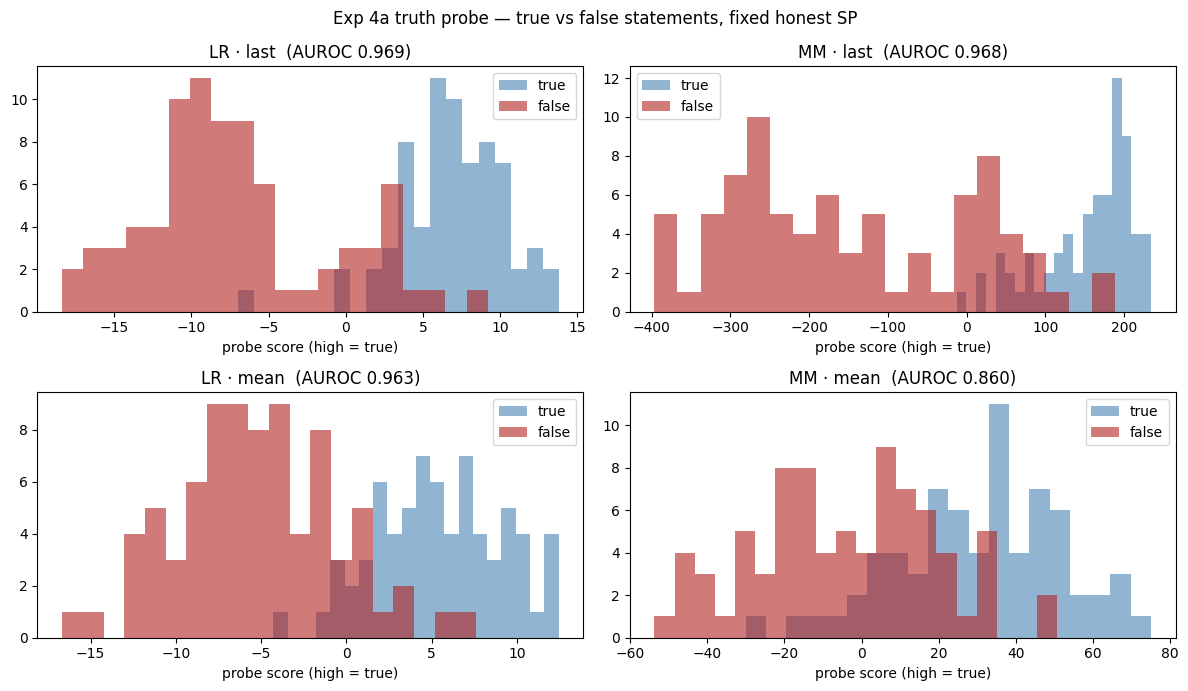

In [5]:
# True vs false score distributions — LR/MM x last/mean
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
panels = [('last','lr_score','LR'), ('last','mm_score','MM'),
          ('mean','lr_score','LR'), ('mean','mm_score','MM')]
for ax, (agg, key, name) in zip(axes.flat, panels):
    scores = probes[agg][key]
    auc = probes[agg][f"{name.lower()}_auroc"]
    for lab, color, nm in [(1,'steelblue','true'), (0,'firebrick','false')]:
        ax.hist(scores[y_test==lab], bins=20, alpha=0.6, label=nm, color=color)
    ax.set_title(f'{name} · {agg}  (AUROC {auc:.3f})')
    ax.set_xlabel('probe score (high = true)'); ax.legend()
plt.suptitle('Exp 4a truth probe — true vs false statements, fixed honest SP')
plt.tight_layout()

## Layer sweep — where does the truth feature live?

L20 is the *SP-shortcut* peak (Exp 1); the *truth* feature may peak elsewhere.
Sweep last-token activations across depth in a single forward pass
(`lib.collect_activations_layers`), fit a fresh LR+MM per layer. M&T find truth
structure emerging early-middle and stabilizing — so watch for an earlier peak.

In [6]:
SWEEP_LAYERS = [4, 8, 12, 16, 20, 24, 28, 32]   # ~11%–89% depth of 36 blocks
SWEEP_CACHE = "truth_sweep"

if lib.cache_exists(SWEEP_CACHE):
    print("Loading cached sweep activations.")
    sb = lib.load_cache(SWEEP_CACHE)
    acts_tr = {L: sb[f"tr_{L}"].float().numpy() for L in SWEEP_LAYERS}
    acts_te = {L: sb[f"te_{L}"].float().numpy() for L in SWEEP_LAYERS}
else:
    print("Extracting sweep activations (no cache, one forward pass per split). Needs GPU.")
    model, tok = lib.load_model_and_tokenizer()
    tr = lib.collect_activations_layers(model, tok, train_prompts, SWEEP_LAYERS, batch_size=8)
    te = lib.collect_activations_layers(model, tok, test_prompts,  SWEEP_LAYERS, batch_size=8)
    lib.save_cache(SWEEP_CACHE,
                   **{f"tr_{L}": tr[L] for L in SWEEP_LAYERS},
                   **{f"te_{L}": te[L] for L in SWEEP_LAYERS},
                   y_train=torch.tensor(y_train), y_test=torch.tensor(y_test))
    acts_tr = {L: tr[L].float().numpy() for L in SWEEP_LAYERS}
    acts_te = {L: te[L].float().numpy() for L in SWEEP_LAYERS}

sweep_rows = []
for L in SWEEP_LAYERS:
    Xtr, Xte = acts_tr[L], acts_te[L]
    lrp = lib.fit_lr_probe(Xtr, y_train)
    dd  = lib.mm_direction(Xtr, y_train)
    sweep_rows.append({'layer': L,
                       'LR': lib.auroc(lrp.decision_function(Xte), y_test),
                       'MM': lib.auroc(lib.mm_score(Xte, dd), y_test)})
sweep_df = pd.DataFrame(sweep_rows).set_index('layer')
print(sweep_df.round(3))
print(f"\nLR peak: L{sweep_df['LR'].idxmax()} = {sweep_df['LR'].max():.3f}   "
      f"MM peak: L{sweep_df['MM'].idxmax()} = {sweep_df['MM'].max():.3f}")
print("(L20 row should match the last-token number from the main 4a cell — same data/split.)")

Extracting sweep activations (no cache, one forward pass per split). Needs GPU.


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

          LR     MM
layer              
4      0.643  0.659
8      0.788  0.750
12     0.839  0.778
16     0.936  0.904
20     0.969  0.968
24     0.955  0.951
28     0.954  0.943
32     0.956  0.925

LR peak: L20 = 0.969   MM peak: L20 = 0.968
(L20 row should match the last-token number from the main 4a cell — same data/split.)


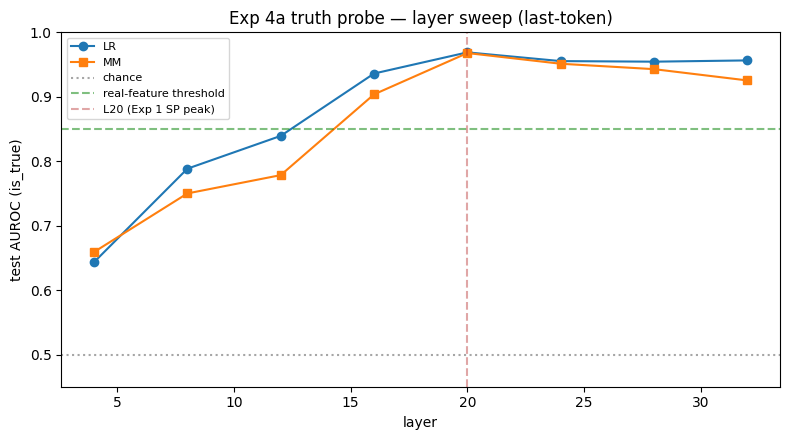

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(sweep_df.index, sweep_df['LR'], marker='o', label='LR')
ax.plot(sweep_df.index, sweep_df['MM'], marker='s', label='MM')
ax.axhline(0.5, color='gray', ls=':', alpha=0.7, label='chance')
ax.axhline(0.85, color='green', ls='--', alpha=0.5, label='real-feature threshold')
ax.axvline(20, color='firebrick', ls='--', alpha=0.4, label='L20 (Exp 1 SP peak)')
ax.set_xlabel('layer'); ax.set_ylabel('test AUROC (is_true)')
ax.set_title('Exp 4a truth probe — layer sweep (last-token)')
ax.set_ylim(0.45, 1.0); ax.legend(fontsize=8)
plt.tight_layout()

## Interpretation (after running)

`# TODO_PETER:` fill after the run, then port the verdict into experiments.md (Exp 4).

- **Truth feature?** L20 AUROC vs the 0.85 threshold. LR vs MM (expect ≈).
- **Gap below Exp 1's 0.998** = how much of Exp 1 was pure SP shortcut.
- **Aggregation:** did last ≥ mean (truth localized), flipping the Exp 3 rule? If so,
  that's the nuance: mean > last only when the signal is diffuse content.
- **Sweep:** where's the peak? Earlier than L20 (M&T early-middle) or at/after it? If
  the peak ≫ L20's value, the L20 default is costing us signal and downstream
  experiments (4b/5) should move to the peak layer.
- **If ~0.5 everywhere:** no linear truth feature at last-token in this 4B model —
  consider raw-text mode (4d) or a different position before giving up.
- Eyeball the false-but-scored-true tail — facts the model plausibly doesn't *know*
  (no mismatch to detect)?

## 4b — Negation generalization: abstract truth, or surface plausibility?

4a found a strong feature (0.97), but we can't yet tell if it's *truth-as-concept*
or a *surface plausibility* feature (M&T `likely` confound — false text just reads
less likely). **This is the decider.**

Take the **4a last-token probe** (`lr`, `d_mm` — no refit) and apply it to
`negation.csv` (100 aff + 100 neg, balanced per form):
- **aff** (e.g. "Paris is the capital of Germany" = false) ≈ training structure →
  should transfer well if the feature is anything truth-like.
- **neg** (e.g. "Paris is **not** the capital of Germany" = **true**) is the real
  test. The minimal pair shares ~all tokens but **flips truth**, so it dissociates
  surface from truth: an abstract-truth probe scores the pair oppositely; a surface
  probe scores them similarly (and gets the negated one wrong). AUROC is rank-based,
  so OOD *calibration* shifts wash out — a low neg-AUROC genuinely means the 4a
  direction fails to *order* negated statements by truth.

Outcomes:
- **neg ≈ aff (both high)** → abstract truth direction. Unambiguous win.
- **neg ≈ 0.5** → surface/plausibility; probe ignores "not".
- **neg < 0.5** → reads surface so hard it scores negated-true as false (antipodal).

A drop is *expected* (M&T: small models, aff-only training) and is **ambiguous**
between (1) surface feature, (2) a real truth feature whose direction is just
misaligned for negated sentences — aff-only training missed the shared axis (M&T
App C), and (3) the model itself not representing negated truth. **4c (aff+neg
balanced training) is the adjudicator:** if it recovers neg performance → it was (2).

**Peter's prediction:** aff ≈ 4a in-dist (distribution is there); neg worse but
still "okay", driven mostly by *narrow (aff-only) training → OOD*, not necessarily
a surface feature. Pre-registers the interpretive ambiguity above. *(Claude's prior:
aff ~0.95, neg drops to 0.55–0.70 — a 4B model likely blends plausibility into the
truth direction and "not" is what surface features fumble.)*

In [8]:
neg = pd.read_csv(DATA_DIR / "negation.csv")
neg_prompts = [lib._make_prompt("an honest", s) for s in neg['statement']]
y_neg = neg['label'].values

NEG_CACHE = f"negation_layer{LAYER}"
if lib.cache_exists(NEG_CACHE):
    print("Loading cached negation activations.")
    X_neg = lib.load_cache(NEG_CACHE)['X_neg'].float().numpy()
else:
    print("Extracting negation activations (no cache). Needs GPU.")
    model, tok = lib.load_model_and_tokenizer()
    X_neg_t = lib.collect_activations(model, tok, neg_prompts, layer=LAYER, batch_size=8)
    lib.save_cache(NEG_CACHE, X_neg=X_neg_t, y_neg=torch.tensor(y_neg))
    X_neg = X_neg_t.float().numpy()
print(f"X_neg: {X_neg.shape}")

Extracting negation activations (no cache). Needs GPU.


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

X_neg: (200, 2560)


In [9]:
# Score with the 4a LAST-TOKEN probe (lr, d_mm carried from the main 4a cell) — NO refit.
neg_scores = pd.DataFrame({
    'form':  neg['form'].values,
    'label': y_neg,
    'lr':    lr.decision_function(X_neg),
    'mm':    lib.mm_score(X_neg, d_mm),
})

rows = []
for subset, mask in [('overall', slice(None)),
                     ('aff', neg_scores.form == 'aff'),
                     ('neg', neg_scores.form == 'neg')]:
    sub = neg_scores[mask]
    rows.append({'subset': subset,
                 'LR': lib.auroc(sub['lr'].values, sub['label'].values),
                 'MM': lib.auroc(sub['mm'].values, sub['label'].values)})
neg_auroc = pd.DataFrame(rows).set_index('subset')
print("4a probe -> negation.csv transfer AUROC (NO refit):")
print(neg_auroc.round(3))
print("\nRef: 4a in-distribution (facts) L20 last-token: LR 0.969, MM 0.968")
print("aff ~ training structure; NEG is the real test.")
print(" neg ~0.85  => abstract truth feature (survives the 'not').")
print(" neg ~0.5   => surface/plausibility; probe ignores negation.")
print(" neg <0.5   => reads surface so hard it scores negated-true as false (antipodal).")

4a probe -> negation.csv transfer AUROC (NO refit):
            LR     MM
subset               
overall  0.879  0.872
aff      0.929  0.924
neg      0.804  0.812

Ref: 4a in-distribution (facts) L20 last-token: LR 0.969, MM 0.968
aff ~ training structure; NEG is the real test.
 neg ~0.85  => abstract truth feature (survives the 'not').
 neg ~0.5   => surface/plausibility; probe ignores negation.
 neg <0.5   => reads surface so hard it scores negated-true as false (antipodal).


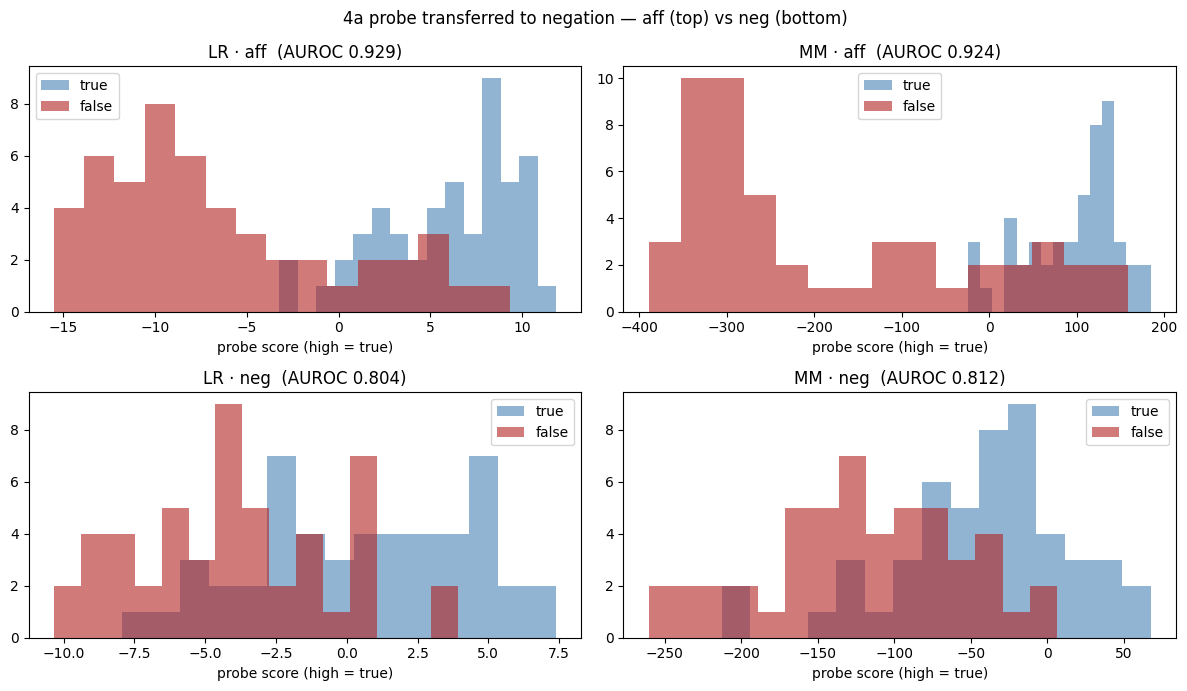

In [10]:
# aff (top) vs neg (bottom); blue=true, red=false. If the probe handles negation,
# the neg-row true/false histograms separate the SAME way as aff. If it reads
# surface, the neg-row separation collapses or flips.
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for r, form in enumerate(['aff', 'neg']):
    sub = neg_scores[neg_scores.form == form]
    for cc, (col, name) in enumerate([('lr', 'LR'), ('mm', 'MM')]):
        ax = axes[r, cc]
        for lab, color, nm in [(1, 'steelblue', 'true'), (0, 'firebrick', 'false')]:
            ax.hist(sub[sub.label == lab][col], bins=15, alpha=0.6, label=nm, color=color)
        auc = lib.auroc(sub[col].values, sub['label'].values)
        ax.set_title(f'{name} · {form}  (AUROC {auc:.3f})')
        ax.set_xlabel('probe score (high = true)'); ax.legend()
plt.suptitle('4a probe transferred to negation — aff (top) vs neg (bottom)')
plt.tight_layout()

## 4b interpretation (after running)

`# TODO_PETER:` fill, then port to experiments.md.

- **aff vs neg AUROC** — the headline. Did neg hold up, collapse to ~0.5, or flip <0.5?
- That answers 4a's open question: **abstract truth** (neg high) vs **surface
  plausibility** (neg ~0.5) vs **antipodal surface** (neg <0.5).
- If neg failed: it's the *expected* M&T small-model result → motivates **4c**
  (train on aff+neg balanced, re-test). If neg held: we have a real truth direction,
  and Exp 5 can steer along it with confidence.
- Sanity: aff AUROC should ≈ the 4a in-dist number (0.969) — if it's much lower,
  something's off in the transfer (tokenization/position), not the hypothesis.